# Notebook 65 — Neural implicit representations

An explicit representation stores geometry directly as points, voxels, or mesh elements. A neural implicit representation instead trains a coordinate-based network to answer questions about arbitrary locations in space.

In this notebook, a small MLP learns a signed-distance field (SDF):

$$
f_\theta(x,y,z) \longrightarrow s.
$$

The predicted scalar $s$ is negative inside the shape, zero on its surface, and positive outside. We use a synthetic field so that every prediction can be compared with a known answer.

Related material:

- [Notebook 63 — 3D representations and geometric intuition](63_3d_representations_and_geometric_intuition.ipynb)
- [Notebook 64 — PointNet and learning from point clouds](64_pointnet_and_point_cloud_learning.ipynb)
- [Neural fields, NeRF, and Gaussian splatting](../notes/15-3d-vision/neural-fields-nerf-and-gaussian-splatting.md)

## Learning goals

- interpret a signed-distance value at a 3D coordinate;
- distinguish stored samples from a continuous query function;
- train a coordinate MLP to approximate a known field;
- recover a surface as the zero level set;
- use field gradients as approximate surface normals;
- understand why Fourier features can help represent fine spatial detail.

In [1]:
from __future__ import annotations

import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("device:", DEVICE)

device: mps


## 1. Signed distance is a field over space

For a sphere with center $c$ and radius $r$, the signed distance at query point $p$ is

$$
s(p)=\lVert p-c\rVert_2-r.
$$

The Euclidean distance $\lVert p-c\rVert_2$ tells us how far the point is from the center. Subtracting the radius moves the zero value from the center to the sphere surface:

- $s(p)<0$: the point is inside;
- $s(p)=0$: the point is on the surface;
- $s(p)>0$: the point is outside.

### Exercise 1 — Implement a sphere SDF (Signed Distance Function)

Calculate one signed distance for every row of `points`. Keep the implementation vectorized.

In [3]:
def sphere_sdf(points, center, radius):
    """Return sphere signed distances for points shaped (N, 3)."""
    # calculate ||point - center||_2 - radius for every point.
    distances = torch.norm(points - center, dim=1) - radius
    return distances


check_points = torch.tensor([
    [0.0, 0.0, 0.0],
    [1.0, 0.0, 0.0],
    [2.0, 0.0, 0.0],
])
check_distances = sphere_sdf(
    check_points, center=torch.zeros(3), radius=1.0
)
torch.testing.assert_close(check_distances, torch.tensor([-1.0, 0.0, 1.0]))
print(check_distances)

tensor([-1.,  0.,  1.])


## 2. Combining simple fields

Our target shape is the union of two overlapping spheres. A point belongs to the union if it belongs to either sphere. For signed distances, the smaller value selects whichever sphere is closer or contains the point more deeply:

$$
s_{union}(p)=\min(s_1(p),s_2(p)).
$$

This minimum gives the exact SDF outside both spheres and the correct zero surface for their union. Around some interior regions it is best treated as a constructive field rather than relying on every strict SDF property.

### Exercise 2 — Build and visualize the target field

Implement the union and evaluate its $z=0$ slice. A 2D slice is only a visualization of the underlying function, which still accepts 3D coordinates.

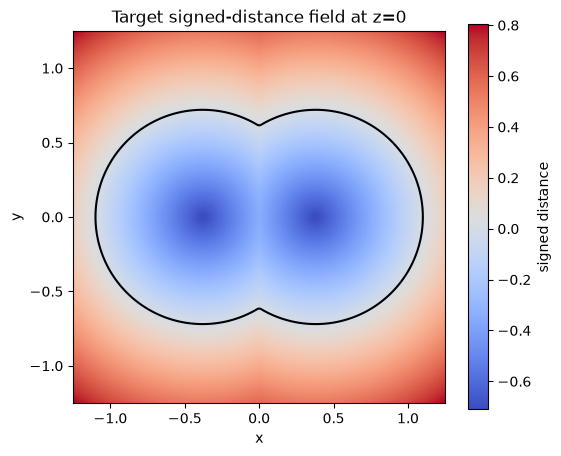

In [5]:
LEFT_CENTER = torch.tensor([-0.38, 0.0, 0.0])
RIGHT_CENTER = torch.tensor([0.38, 0.0, 0.0])
SPHERE_RADIUS = 0.72
COORDINATE_BOUND = 1.25


def target_sdf(points):
    # calculate both sphere fields and return their pointwise minimum.
    left_sdf = sphere_sdf(points, LEFT_CENTER, SPHERE_RADIUS)
    right_sdf = sphere_sdf(points, RIGHT_CENTER, SPHERE_RADIUS)
    return torch.minimum(left_sdf, right_sdf)


resolution = 160
# Select 160 evenly spaced coordinates along both the x and y axes.
axis_values = torch.linspace(-COORDINATE_BOUND, COORDINATE_BOUND, resolution)
# Turn the 1D values into two (160, 160) grids. With indexing="ij",
# rows vary along y and columns vary along x, matching image indexing.
grid_y, grid_x = torch.meshgrid(axis_values, axis_values, indexing="ij")
# Flatten both grids and pair corresponding x and y values. Setting every
# z value to zero creates resolution**2 query points on the z=0 plane.
slice_points = torch.stack(
    (grid_x.ravel(), grid_y.ravel(), torch.zeros(resolution**2)), dim=1
)

# The field returns one value per flat query. Reshape those values back to
# the same row-and-column layout as grid_x and grid_y for visualization.
target_slice = target_sdf(slice_points).reshape(resolution, resolution)

assert target_slice.shape == (resolution, resolution)

fig, axis = plt.subplots(figsize=(6, 5))
image = axis.imshow(
    target_slice.numpy(),
    origin="lower",
    extent=(-COORDINATE_BOUND, COORDINATE_BOUND) * 2,
    cmap="coolwarm",
)
axis.contour(grid_x.numpy(), grid_y.numpy(), target_slice.numpy(), levels=[0.0], colors="black")
axis.set(title="Target signed-distance field at z=0", xlabel="x", ylabel="y", aspect="equal")
fig.colorbar(image, ax=axis, label="signed distance")
plt.show()

## 3. A coordinate MLP stores a function, not a grid

A voxel grid stores a separate value for every cell. A coordinate MLP stores weights $\theta$ and computes a value only when we query a coordinate. For a batch of $N$ queries, the dimensions are

$$
(N,3)\rightarrow(N,H)\rightarrow(N,H)\rightarrow(N,1).
$$

The final singleton dimension is removed so predictions have shape $(N,)$, matching one scalar target per coordinate.

### Exercise 3 — Complete the coordinate network

Add the layers and return one scalar prediction per coordinate.

In [6]:
class CoordinateMLP(nn.Module):
    """Approximate a scalar field from 3D coordinate queries."""

    def __init__(self, hidden_dim=64):
        super().__init__()
        self.network = nn.Sequential(
            # 3 -> hidden -> hidden -> 1 with ReLU activations.
            nn.Linear(3, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, coordinates):
        # evaluate the network and remove only the final size-one axis.
        return self.network(coordinates).squeeze(-1)


coordinate_model = CoordinateMLP(hidden_dim=64)
example_predictions = coordinate_model(torch.randn(7, 3))
assert example_predictions.shape == (7,)
print(coordinate_model)

CoordinateMLP(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 4. Learn the field from sampled coordinates

The model never receives a voxel grid or mesh. Training data consists only of coordinate–value pairs:

$$
(p_i, s_i), \qquad s_i=s_{target}(p_i).
$$

We sample coordinates uniformly throughout a bounding cube. Mean squared error encourages the predicted field value to match the analytic value.

### Exercise 4 — Complete the optimization step

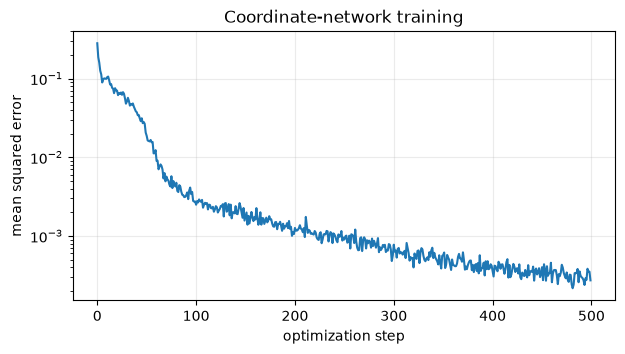

final minibatch loss: 0.000273


In [ ]:
torch.manual_seed(SEED)
number_training_points = 8_000
# torch.rand produces independent x, y, and z values in [0, 1). Scaling
# by 2 * bound gives [0, 2 * bound), and subtracting bound shifts the
# interval to [-bound, bound), so the rows uniformly sample the 3D cube.
training_coordinates = (
    2 * COORDINATE_BOUND * torch.rand(number_training_points, 3)
    - COORDINATE_BOUND
)
training_targets = target_sdf(training_coordinates)

coordinate_model = CoordinateMLP(hidden_dim=64).to(DEVICE)
optimizer = torch.optim.Adam(coordinate_model.parameters(), lr=2e-3)
loss_function = nn.MSELoss()
losses = []

for step in range(500):
    indices = torch.randint(0, number_training_points, (512,))
    coordinate_batch = training_coordinates[indices].to(DEVICE)
    target_batch = training_targets[indices].to(DEVICE)

    # predict distances, calculate loss, and update the model.
    loss = loss_function(coordinate_model(coordinate_batch), target_batch)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

plt.figure(figsize=(7, 3.5))
plt.plot(losses)
plt.yscale("log")
plt.xlabel("optimization step")
plt.ylabel("mean squared error")
plt.title("Coordinate-network training")
plt.grid(alpha=0.25)
plt.show()
print(f"final minibatch loss: {losses[-1]:.6f}")

In [14]:
(
    torch.mean(training_targets),
    torch.std(training_targets)
)

(tensor(0.3392), tensor(0.3341))

## 5. Recover the zero level set

The network does not directly output surface points. It predicts a scalar everywhere, and the surface is the set of locations where that scalar equals zero:

$$
\mathcal{S}=\{p:f_\theta(p)=0\}.
$$

In 2D, `contour(..., levels=[0])` traces this zero crossing. In 3D, an algorithm such as marching cubes can extract a triangle mesh from sampled field values.

### Exercise 5 — Compare the learned and target fields

Evaluate the trained network on the same $z=0$ slice and reshape its flat predictions back into an image.

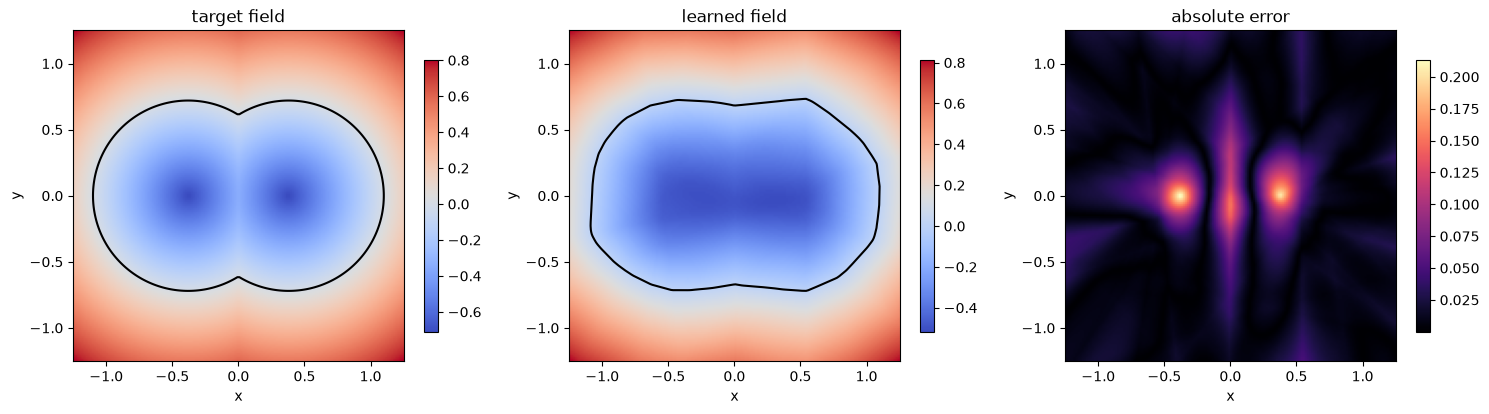

slice mean absolute error: 0.02003


In [18]:
coordinate_model.eval()
with torch.no_grad():
    # predict all slice coordinates and reshape to the grid.
    predicted_slice = coordinate_model(
        slice_points.to(DEVICE)
    ).cpu().reshape(resolution, resolution)

assert predicted_slice.shape == target_slice.shape
absolute_error = (predicted_slice - target_slice).abs()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, values, title in zip(
    axes,
    (target_slice, predicted_slice, absolute_error),
    ("target field", "learned field", "absolute error"),
):
    image = axis.imshow(
        values.numpy(),
        origin="lower",
        extent=(-COORDINATE_BOUND, COORDINATE_BOUND) * 2,
        cmap="magma" if title == "absolute error" else "coolwarm",
    )
    if title != "absolute error":
        axis.contour(grid_x.numpy(), grid_y.numpy(), values.numpy(), levels=[0.0], colors="black")
    axis.set(title=title, xlabel="x", ylabel="y", aspect="equal")
    fig.colorbar(image, ax=axis, shrink=0.8)
plt.tight_layout()
plt.show()
print(f"slice mean absolute error: {absolute_error.mean():.5f}")

## 6. Continuous queries versus stored resolution

The MLP has no fixed spatial resolution. The same trained weights can be queried on a $32\times32$ slice or a $256\times256$ slice without retraining. A denser query grid creates a smoother visualization, but it does not add information to the learned function. It also requires more network evaluations.

This differs from a voxel grid, whose stored resolution and memory allocation are fixed when the grid is created.

### Exercise 6 — Query several visualization resolutions

Complete the helper. Record both the number of coordinate queries and evaluation time. Timing may be noisy, especially for very short accelerator operations, so focus on the overall trend.

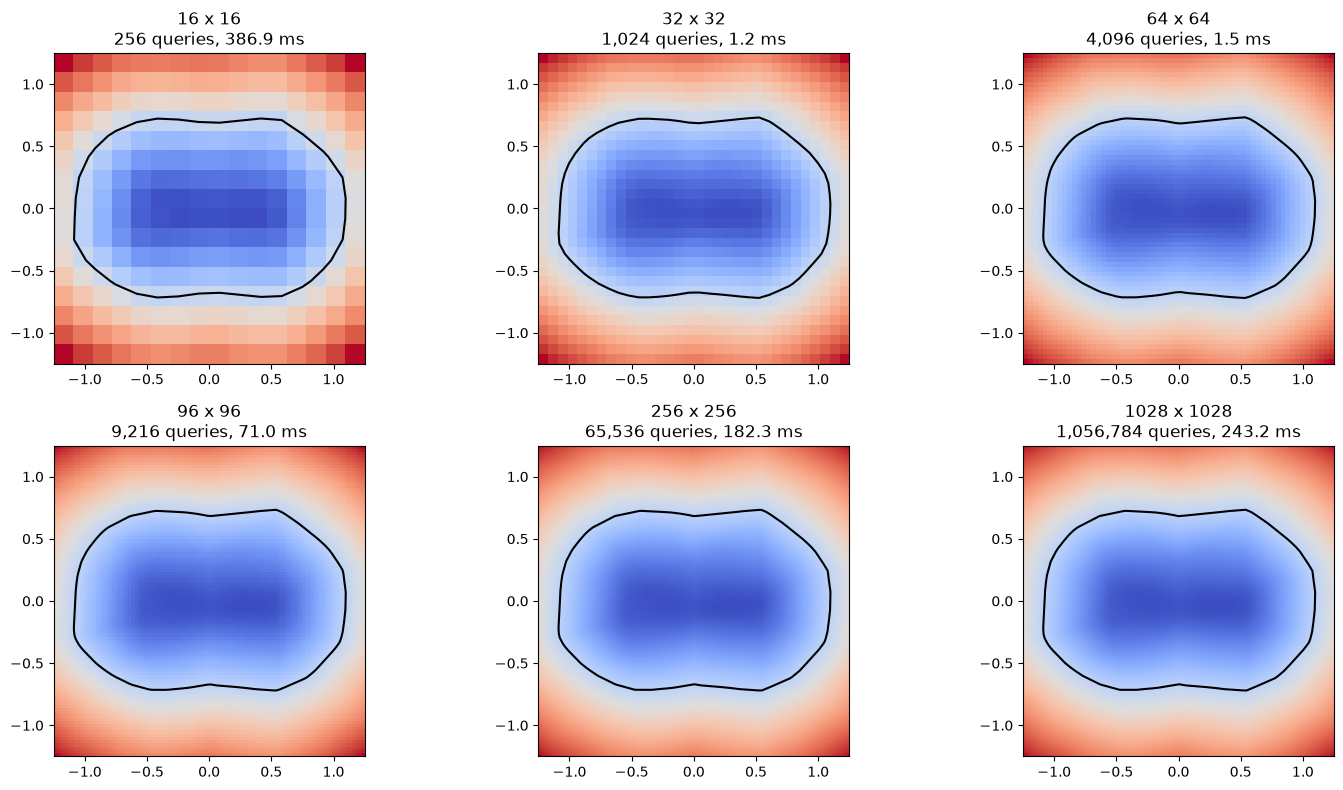

In [20]:
def evaluate_slice(model, resolution, *, device, batch_size=65_536):
    values = torch.linspace(-COORDINATE_BOUND, COORDINATE_BOUND, resolution)
    query_y, query_x = torch.meshgrid(values, values, indexing="ij")
    queries = torch.stack(
        (query_x.ravel(), query_y.ravel(), torch.zeros(resolution**2)),
        dim=1,
    )
    start = time.perf_counter()
    with torch.no_grad():
        # Process large grids in batches so high-resolution queries do not
        # require every hidden activation to fit on the device at once.
        prediction_batches = [
            model(query_batch.to(device)).cpu()
            for query_batch in queries.split(batch_size)
        ]
        field = torch.cat(prediction_batches).reshape(resolution, resolution)
    elapsed = time.perf_counter() - start
    return query_x, query_y, field, elapsed


query_resolutions = (16, 32, 64, 96, 256, 1028)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, query_resolution in zip(axes.ravel(), query_resolutions):
    query_x, query_y, field, elapsed = evaluate_slice(
        coordinate_model, query_resolution, device=DEVICE
    )
    axis.imshow(
        field.numpy(),
        origin="lower",
        extent=(-COORDINATE_BOUND, COORDINATE_BOUND) * 2,
        cmap="coolwarm",
    )
    axis.contour(query_x.numpy(), query_y.numpy(), field.numpy(), levels=[0.0], colors="black")
    axis.set(
        title=f"{query_resolution} x {query_resolution}\n{query_resolution**2:,} queries, {elapsed * 1_000:.1f} ms",
        aspect="equal",
    )
plt.tight_layout()
plt.show()

## 7. Field gradients provide surface directions

For a differentiable field, the gradient with respect to the input coordinate is

$$
\nabla_p f_\theta(p)=
\left[
\frac{\partial f}{\partial x},
\frac{\partial f}{\partial y},
\frac{\partial f}{\partial z}
\right].
$$

This is the gradient of the model's predicted field value with respect to its input coordinate. It is **not** the gradient of the training loss. The two uses of differentiation are:

$$
\frac{\partial L}{\partial \theta}
\quad\text{for training the model,}
\qquad
\frac{\partial f_\theta}{\partial p}
\quad\text{for measuring how the field changes in space.}
$$

The first tells us how to update the parameters $\theta$ to reduce loss. The second keeps the trained parameters fixed and asks how the predicted SDF changes if the query point moves slightly in $x$, $y$, or $z$.

Our SDF is negative inside, zero on the surface, and positive outside. A gradient points toward the direction of greatest increase, so at a smooth surface it points from negative values toward positive values: outward. For the analytic sphere,

$$
\nabla_p(\lVert p-c\rVert_2-r)
=\frac{p-c}{\lVert p-c\rVert_2},
$$

which is a vector from the sphere center toward the query point. Reversing the SDF sign convention would reverse this direction. Dividing a learned field gradient by its Euclidean norm gives a unit-length approximate surface normal.

### Exercise 7 — Calculate approximate normals

Use `torch.autograd.grad` to differentiate the sum of predictions with respect to the query coordinates. `autograd.grad` can directly differentiate a scalar, so the batch predictions are summed first. Because this coordinate MLP processes every row independently, prediction $i$ depends only on query point $i$. The resulting gradient therefore still contains one $(x,y,z)$ gradient vector for every input row; the sum does not mix their spatial derivatives.

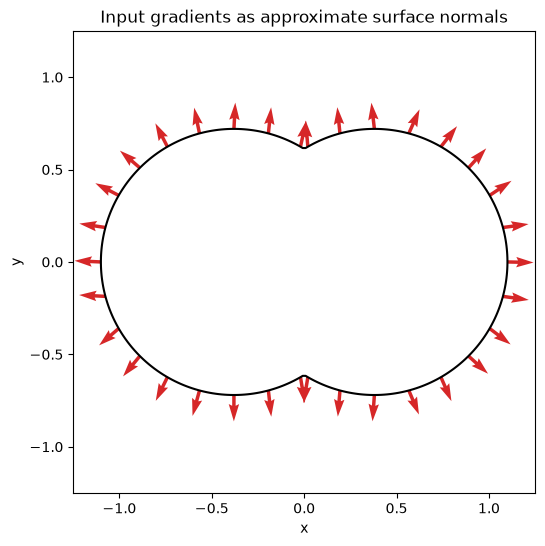

In [27]:
angles = torch.linspace(0.0, 2.0 * torch.pi, 25)[:-1]
left_surface_points = torch.stack(
    (
        LEFT_CENTER[0] + SPHERE_RADIUS * torch.cos(angles),
        SPHERE_RADIUS * torch.sin(angles),
        torch.zeros_like(angles),
    ),
    dim=1,
)
right_surface_points = left_surface_points.clone()
right_surface_points[:, 0] += RIGHT_CENTER[0] - LEFT_CENTER[0]

# Remove circle segments hidden inside the other sphere's union.
left_visible = sphere_sdf(left_surface_points, RIGHT_CENTER, SPHERE_RADIUS) >= 0
right_visible = sphere_sdf(right_surface_points, LEFT_CENTER, SPHERE_RADIUS) >= 0
surface_points = torch.cat(
    (left_surface_points[left_visible], right_surface_points[right_visible])
).to(DEVICE)
surface_points.requires_grad_(True)

surface_predictions = coordinate_model(surface_points)
# differentiate predictions.sum() with respect to surface_points.
field_gradients = torch.autograd.grad(
    outputs=surface_predictions.sum(),
    inputs=surface_points,
)[0]
# normalize each gradient vector along its coordinate axis.
estimated_normals = field_gradients / field_gradients.norm(dim=1, keepdim=True)

assert field_gradients.shape == surface_points.shape
torch.testing.assert_close(
    estimated_normals.norm(dim=1),
    torch.ones(len(surface_points), device=DEVICE),
    atol=1e-5,
    rtol=1e-5,
)

points_np = surface_points.detach().cpu().numpy()
normals_np = estimated_normals.detach().cpu().numpy()
plt.figure(figsize=(6, 6))
plt.contour(grid_x.numpy(), grid_y.numpy(), target_slice.numpy(), levels=[0.0], colors="black")
plt.quiver(
    points_np[:, 0],
    points_np[:, 1],
    normals_np[:, 0],
    normals_np[:, 1],
    color="tab:red",
    angles="xy",
    scale_units="xy",
    scale=7,
)
plt.xlim(-COORDINATE_BOUND, COORDINATE_BOUND)
plt.ylim(-COORDINATE_BOUND, COORDINATE_BOUND)
plt.gca().set_aspect("equal")
plt.title("Input gradients as approximate surface normals")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## 8. Fourier features expose several spatial frequencies

Ordinary ReLU MLPs often learn smooth, low-frequency variation before fine detail. Coordinate-based models therefore often encode each coordinate with sine and cosine functions at several frequencies. For a scalar coordinate $x$, one possible encoding is

$$
\gamma(x)=
[\sin(2^0\pi x),\cos(2^0\pi x),\ldots,
\sin(2^{L-1}\pi x),\cos(2^{L-1}\pi x)].
$$

The encoding is a fixed nonlinear transformation; it does not learn the answer or contain trainable parameters. It expands a small raw coordinate into a larger collection of signals that change at different spatial scales.

A linear model placed after this encoding can already learn weighted combinations such as

$$
\hat f(x)=a_0x+\sum_k
[a_k\sin(2^k\pi x)+b_k\cos(2^k\pi x)].
$$

Although the learned combination is linear in the coefficients $a_k$ and $b_k$, its output is nonlinear in the original coordinate $x$ because its inputs are sine and cosine features. This can be enough for a function composed of the supplied frequencies.

Fourier features are not generally a complete replacement for hidden layers. A simple linear model is restricted to the basis functions we supplied and cannot easily learn all complex interactions among $x$, $y$, and $z$. An MLP after the encoding can learn nonlinear combinations and interactions between those features. The common design is therefore

```text
raw coordinates -> fixed Fourier encoding -> learned MLP -> field value
```

A sufficiently large raw-coordinate MLP can theoretically represent detailed functions too. In practice, ordinary MLPs tend to learn smooth, low-frequency structure before rapid variation—an optimization behavior called **spectral bias**. Fourier features expose useful frequencies directly, often making fine detail easier to learn than merely increasing MLP width or depth. NeRF uses a closely related positional encoding for positions and viewing directions and still follows it with an MLP.

For inputs shaped $(N,3)$ and $L$ frequencies, concatenating the original coordinates with sine and cosine values produces width

$$
3+2\cdot3\cdot L.
$$

### Exercise 8 — Implement Fourier feature encoding

Keep all original coordinates, then append sine and cosine features for every frequency.

In [32]:
def fourier_encode(coordinates, number_frequencies):
    """Encode (N, D) coordinates with powers-of-two frequencies."""
    # Create L powers-of-two frequencies with shape (L,): 1, 2, 4, ...
    frequencies = 2.0 ** torch.arange(
        number_frequencies, dtype=coordinates.dtype, device=coordinates.device
    )
    # (N, D) -> (N, 1, D), while frequencies become (1, L, 1).
    # Broadcasting pairs every coordinate with every frequency, producing
    # angles shaped (N, L, D). The pi factor matches the formula above.
    angles = (
        torch.pi
        * coordinates[:, None, :]
        * frequencies[None, :, None]
    )
    # Sine and cosine describe complementary phases at the same frequencies.
    sin_features = torch.sin(angles)
    cos_features = torch.cos(angles)
    # Flatten (L, D) into L*D features per example, then preserve the
    # original coordinates before appending all sine and cosine features.
    encoded = torch.cat(
        (
            coordinates,
            sin_features.flatten(start_dim=1),
            cos_features.flatten(start_dim=1),
        ),
        dim=1,
    )
    return encoded


encoded = fourier_encode(torch.tensor([[0.1, 0.2, 0.3]]), 4)
assert encoded.shape == (1, 3 + 2 * 3 * 4)
torch.testing.assert_close(encoded[:, :3], torch.tensor([[0.1, 0.2, 0.3]]))
print("original shape: (1, 3)")
print("encoded shape: ", tuple(encoded.shape))

original shape: (1, 3)
encoded shape:  (1, 27)


In [34]:
encoded

tensor([[ 0.1000,  0.2000,  0.3000,  0.3090,  0.5878,  0.8090,  0.5878,  0.9511,
          0.9511,  0.9511,  0.5878, -0.5878,  0.5878, -0.9511,  0.9511,  0.9511,
          0.8090,  0.5878,  0.8090,  0.3090, -0.3090,  0.3090, -0.8090, -0.8090,
         -0.8090,  0.3090,  0.3090]])

### Visualizing the encoded frequencies

The plots below encode one scalar coordinate $x$ while it moves from $-1$ to $1$. Every panel receives exactly the same coordinate values. Only the frequency changes.

Low-frequency features vary slowly and distinguish broad spatial regions. Higher-frequency features complete more oscillations over the same interval and can distinguish nearby positions more precisely. Sine and cosine are included together so the representation contains both phases of each frequency.

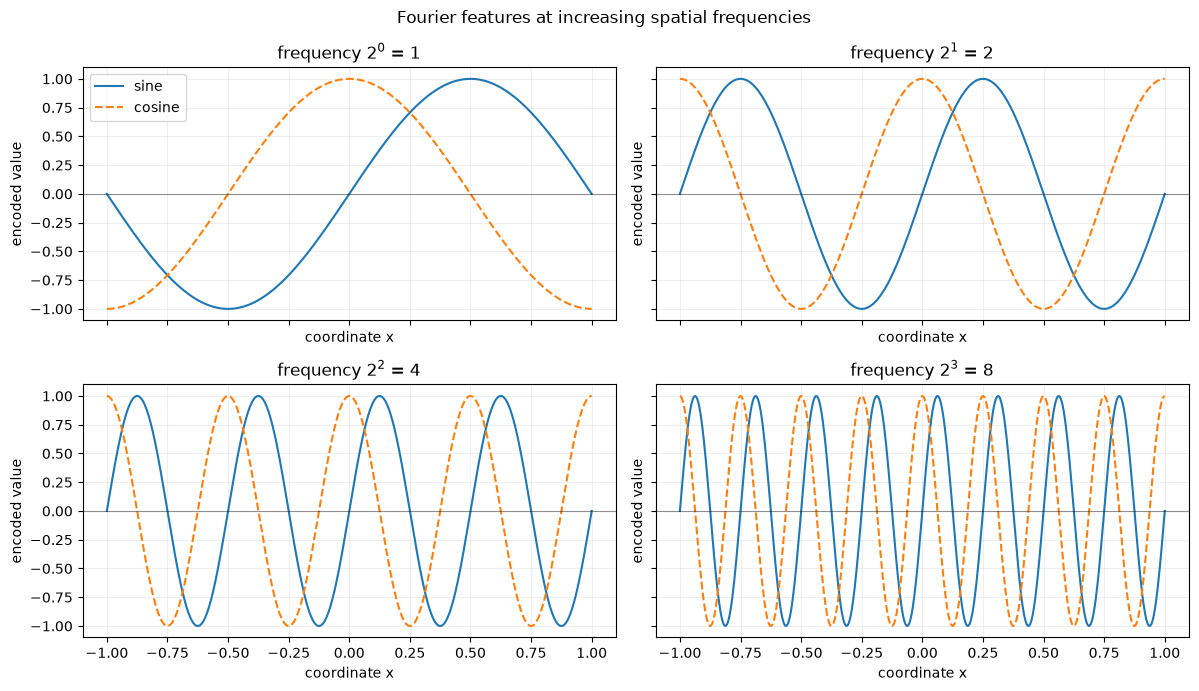

In [33]:
number_frequencies = 4
line_coordinates = torch.linspace(-1.0, 1.0, 500).unsqueeze(1)
encoded_line = fourier_encode(line_coordinates, number_frequencies)

# With one input dimension, column 0 is the original x coordinate, the
# next L columns are sine features, and the final L are cosine features.
sine_start = 1
cosine_start = 1 + number_frequencies

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for frequency_index, axis in enumerate(axes.ravel()):
    frequency = 2**frequency_index
    axis.plot(
        line_coordinates[:, 0],
        encoded_line[:, sine_start + frequency_index],
        label="sine",
    )
    axis.plot(
        line_coordinates[:, 0],
        encoded_line[:, cosine_start + frequency_index],
        linestyle="--",
        label="cosine",
    )
    axis.axhline(0.0, color="black", linewidth=0.8, alpha=0.4)
    axis.set_title(f"frequency $2^{frequency_index}$ = {frequency}")
    axis.set_xlabel("coordinate x")
    axis.set_ylabel("encoded value")
    axis.grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle("Fourier features at increasing spatial frequencies")
plt.tight_layout()
plt.show()

## 9. Connection to NeRF

This notebook learns

```text
3D coordinate -> signed distance
```

A NeRF-style network instead learns something closer to

```text
3D coordinate + viewing direction -> density + color
```

The coordinate-network idea is the same, but producing an image requires additional machinery: camera rays, multiple samples along each ray, and visibility-aware volume rendering. We keep those ideas conceptual in the accompanying notes rather than expanding this intuition-first practice into a full NeRF implementation.

## Reflection

1. What information does the sign of an SDF value provide?

   **Answer:** A negative value means the point is inside, zero identifies the surface, and a positive value means the point is outside. Its magnitude approximates distance to the surface.

2. Why is a coordinate MLP called an implicit representation?

   **Answer:** Instead of explicitly storing surface elements or one value per grid cell, the network parameters define a function that returns a field value for any queried coordinate.

3. Where is the surface stored in this model?

   **Answer:** The surface is not stored explicitly. It is implicitly defined by all coordinates where the learned function has value zero: $f_\theta(p)=0$.

4. Why can the trained model be evaluated at a new spatial resolution?

   **Answer:** The MLP processes independent coordinate rows and does not require a fixed grid size. Resolution changes only how many coordinates we choose to query.

5. What is the difference between increasing query resolution and improving the learned field?

   **Answer:** Increasing query resolution samples the same learned function more densely and makes its visualization smoother; it does not make the function more accurate. Improving the field changes the learned function itself through better training data, optimization, or model capacity.

6. What does the input gradient of an SDF represent near its surface?

   **Answer:** It gives the direction in which the predicted SDF increases most rapidly. With negative values inside and positive values outside, its normalized direction is an approximate outward surface normal.

7. Why might Fourier features help a coordinate network?

   **Answer:** They provide fixed nonlinear signals at several spatial frequencies, helping the network learn fine, rapidly changing detail despite the low-frequency preference of ordinary coordinate MLPs.

8. What extra operations are needed to turn a NeRF field into a rendered pixel?

   **Answer:** Cast a camera ray through the pixel, sample 3D positions along it, predict density and color at those samples, and combine them with visibility-aware volume-rendering weights.